# Heart Disease Prediction using Machine Learning

Classifies whether a person has heart disease using **K-Nearest Neighbors** and **Random Forest**.

Based on my research paper *"Heart Disease Prediction Using Machine Learning"* (2nd Best Paper Presentation Award, International Conference of Emerging Vista's of Computer Science, IT and Management in 21st Century, Parul University, March 2024).

**Dataset:** Heart disease dataset from Kaggle (303 rows, 13 features + `target`: 1 = heart disease, 0 = no heart disease). Place the CSV in the same folder as this notebook and name it `heart.csv`.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

## 1. Load and explore the data

In [5]:
df = pd.read_csv('heart.csv')
df = df.drop(columns=['Unnamed: 0'])
df = df.rename(columns={'Age':'age','Sex':'sex','ChestPain':'cp','RestBP':'trestbps','Chol':'chol','Fbs':'fbs','RestECG':'restecg','MaxHR':'thalach','ExAng':'exang','Oldpeak':'oldpeak','Slope':'slope','Ca':'ca','Thal':'thal','AHD':'target'})
df['target'] = df['target'].map({'Yes': 1, 'No': 0})
df['ca'] = df['ca'].fillna(df['ca'].mode()[0])
df['thal'] = df['thal'].fillna(df['thal'].mode()[0])
# text columns -> numeric codes
df['cp'] = df['cp'].astype('category').cat.codes
df['thal'] = df['thal'].astype('category').cat.codes
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int8   
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    float64
 12  thal      303 non-null    int8   
 13  target    303 non-null    int64  
dtypes: float64(2), int64(10), int8(2)
memory usage: 29.1 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,0.841584,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.663366,1.326733,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,0.583020,0.499120
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,1.000000,0.000000
75%,61.000000,1.000000,1.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,2.000000,1.000000


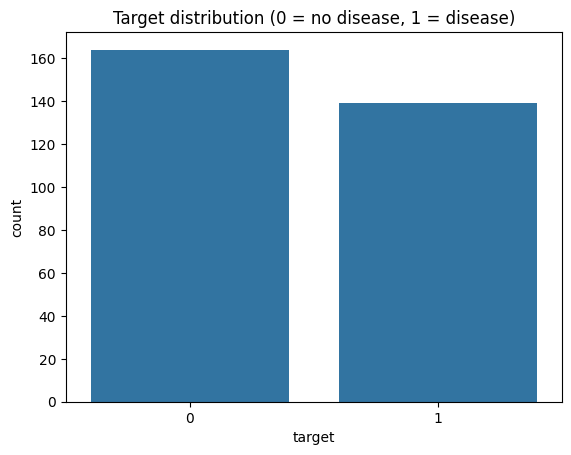

In [6]:
# Is the target balanced?
sns.countplot(x='target', data=df)
plt.title('Target distribution (0 = no disease, 1 = disease)')
plt.show()

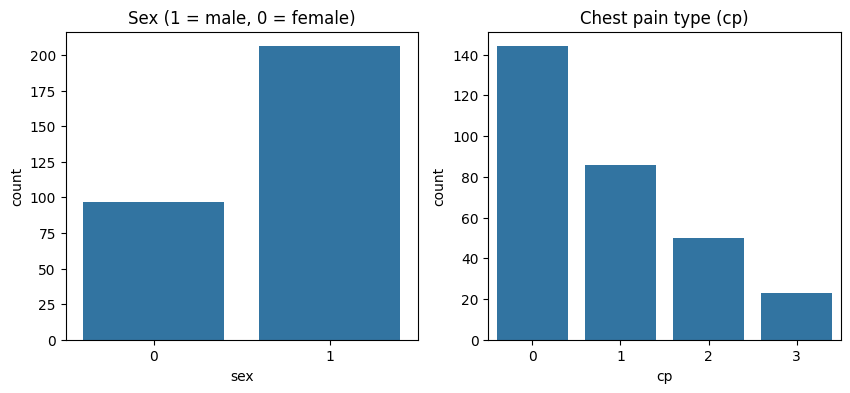

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='sex', data=df, ax=ax[0]); ax[0].set_title('Sex (1 = male, 0 = female)')
sns.countplot(x='cp', data=df, ax=ax[1]);  ax[1].set_title('Chest pain type (cp)')
plt.show()

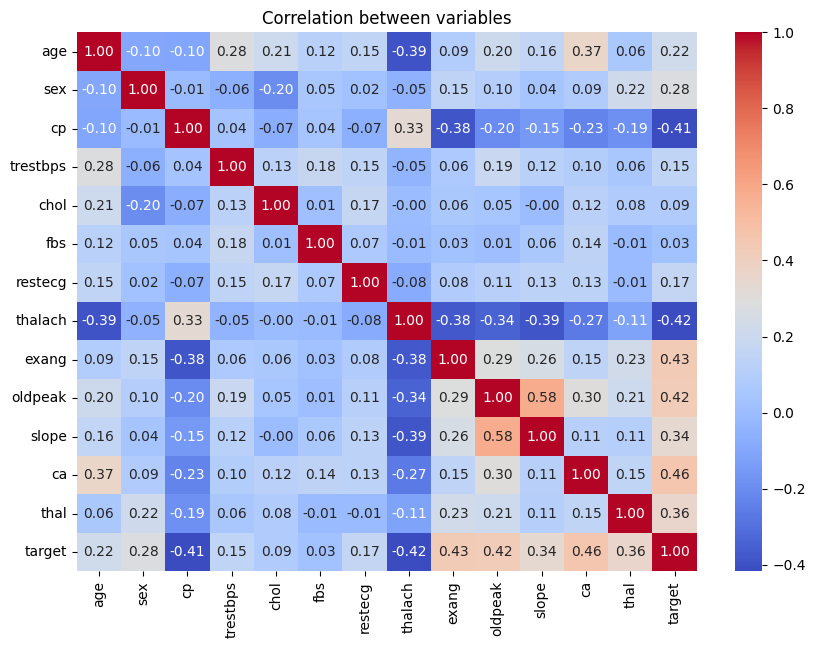

In [8]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between variables')
plt.show()

## 2. Preprocessing
Categorical columns are converted to dummy variables and numeric columns are standardised.

In [9]:
categorical = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
numeric = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

data = pd.get_dummies(df, columns=categorical)
data[numeric] = StandardScaler().fit_transform(data[numeric])

X = data.drop('target', axis=1)
y = data['target']

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(X_train.shape, X_test.shape)

(242, 28) (61, 28)


## 3. K-Nearest Neighbors
Try different values of K and pick the best one (the paper used K = 12).

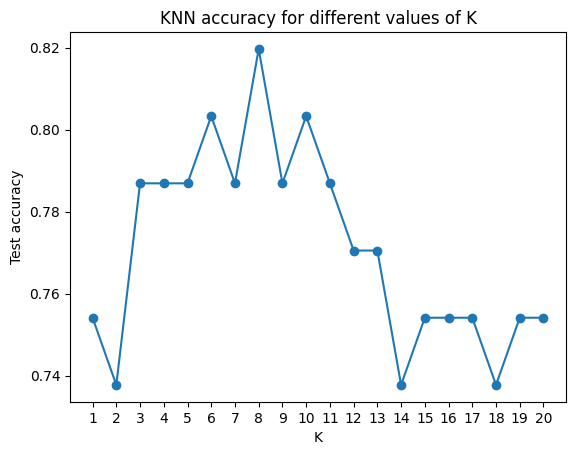

In [10]:
scores = []
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    scores.append(knn.score(X_test, y_test))

plt.plot(range(1, 21), scores, marker='o')
plt.xticks(range(1, 21))
plt.xlabel('K'); plt.ylabel('Test accuracy')
plt.title('KNN accuracy for different values of K')
plt.show()

In [11]:
knn = KNeighborsClassifier(n_neighbors=12).fit(X_train, y_train)
knn_pred = knn.predict(X_test)
print('KNN confusion matrix:\n', confusion_matrix(y_test, knn_pred))
print('KNN accuracy: %.2f%%' % (accuracy_score(y_test, knn_pred) * 100))

KNN confusion matrix:
 [[29  6]
 [ 8 18]]
KNN accuracy: 77.05%


## 4. Random Forest
The paper used 10 trees.

In [12]:
rf = RandomForestClassifier(n_estimators=10, random_state=0).fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print('Random Forest confusion matrix:\n', confusion_matrix(y_test, rf_pred))
print('Random Forest accuracy: %.2f%%' % (accuracy_score(y_test, rf_pred) * 100))

Random Forest confusion matrix:
 [[31  4]
 [ 8 18]]
Random Forest accuracy: 80.33%


## 5. Results comparison

In [13]:
results = pd.DataFrame({
    'Model': ['K-Nearest Neighbors (K=12)', 'Random Forest (10 trees)'],
    'Accuracy (%)': [accuracy_score(y_test, knn_pred) * 100, accuracy_score(y_test, rf_pred) * 100]
}).round(2)
results

,Model,Accuracy (%)
0,K-Nearest Neighbors (K=12),77.05
1,Random Forest (10 trees),80.33


## Results in the paper
| Model | Accuracy |
|---|---|
| K-Nearest Neighbors (K = 12) | 86.89% |
| Random Forest (10 trees) | 81.97% |

Exact numbers in this notebook can differ slightly depending on the train/test split (`random_state`).

## Tech stack
Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn